# Residual Noise Method - Noise Reduction Analysis

## Method Explanation

Since we don't have ground-truth force measurements, we use the **Residual Noise Method** to quantify noise reduction. This is a standard approach in robotics and haptics papers.

### The Concept:

1. **Raw Signal** `x(t)`: FRaw - the noisy force measurement
2. **Filtered Signal** `x~(t)`: FF_EE or predicted_force - the smoothed/denoised version
3. **Residual** `r(t) = x(t) - x~(t)`: The difference between raw and filtered
   - This residual represents the noise that was removed by filtering/prediction
   - If the filtered signal captures the true underlying force, the residual is noise

### Why This Works:

- The filtered signal (FF_EE) is assumed to represent the smooth underlying force
- The difference between raw and filtered captures what the filter removed → noise
- We don't need ground truth or constant-force regions
- Works for dynamic motions where force is always changing

### Metrics Calculated:

1. **RMS Noise**: RMS of the residual signal (noise estimate)
2. **RMS Raw**: RMS of the original raw signal  
3. **Noise Reduction %**: `100 × (1 - RMS_noise / RMS_raw)`
4. **Noise Reduction (dB)**: `20 × log10(RMS_raw / RMS_noise)`

### Comparison:

- **FF_EE vs Raw**: How much noise does the 5Hz low-pass filter remove?
- **Predicted vs Raw**: How much noise does the MLP model prediction remove?


In [1]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

# Load the predictions dataset
data_path = Path('mlp_predictions_dataset.jsonl')

print(f"Loading data from {data_path}...")
data_points = []
with open(data_path, 'r') as f:
    for line in f:
        if line.strip():
            data_points.append(json.loads(line))

print(f"✓ Loaded {len(data_points)} data points")

# Extract the three force signals
FRaw = np.array([dp['FRaw'] for dp in data_points])  # Shape: (N, 6) - x(t)
FF_EE = np.array([dp['FF_EE'] for dp in data_points])  # Shape: (N, 6) - x~(t) filtered
predicted_force = np.array([dp['predicted_force'] for dp in data_points])  # Shape: (N, 6) - x~(t) predicted

print(f"\nData shapes:")
print(f"  FRaw (x(t)): {FRaw.shape}")
print(f"  FF_EE (x~_filtered(t)): {FF_EE.shape}")
print(f"  predicted_force (x~_predicted(t)): {predicted_force.shape}")

# Calculate sampling frequency
timestamps = np.array([dp['timestamp'] for dp in data_points])
mean_freq = 1.0 / np.mean(np.diff(timestamps))
print(f"\nMean sampling frequency: {mean_freq:.2f} Hz")


Loading data from mlp_predictions_dataset.jsonl...
✓ Loaded 48745 data points

Data shapes:
  FRaw (x(t)): (48745, 6)
  FF_EE (x~_filtered(t)): (48745, 6)
  predicted_force (x~_predicted(t)): (48745, 6)

Mean sampling frequency: 250.00 Hz


STEP 1: COMPUTING RESIDUAL SIGNALS (NOISE ESTIMATES)
Residual shapes:
  residual_ffee: (48745, 6)
  residual_pred: (48745, 6)


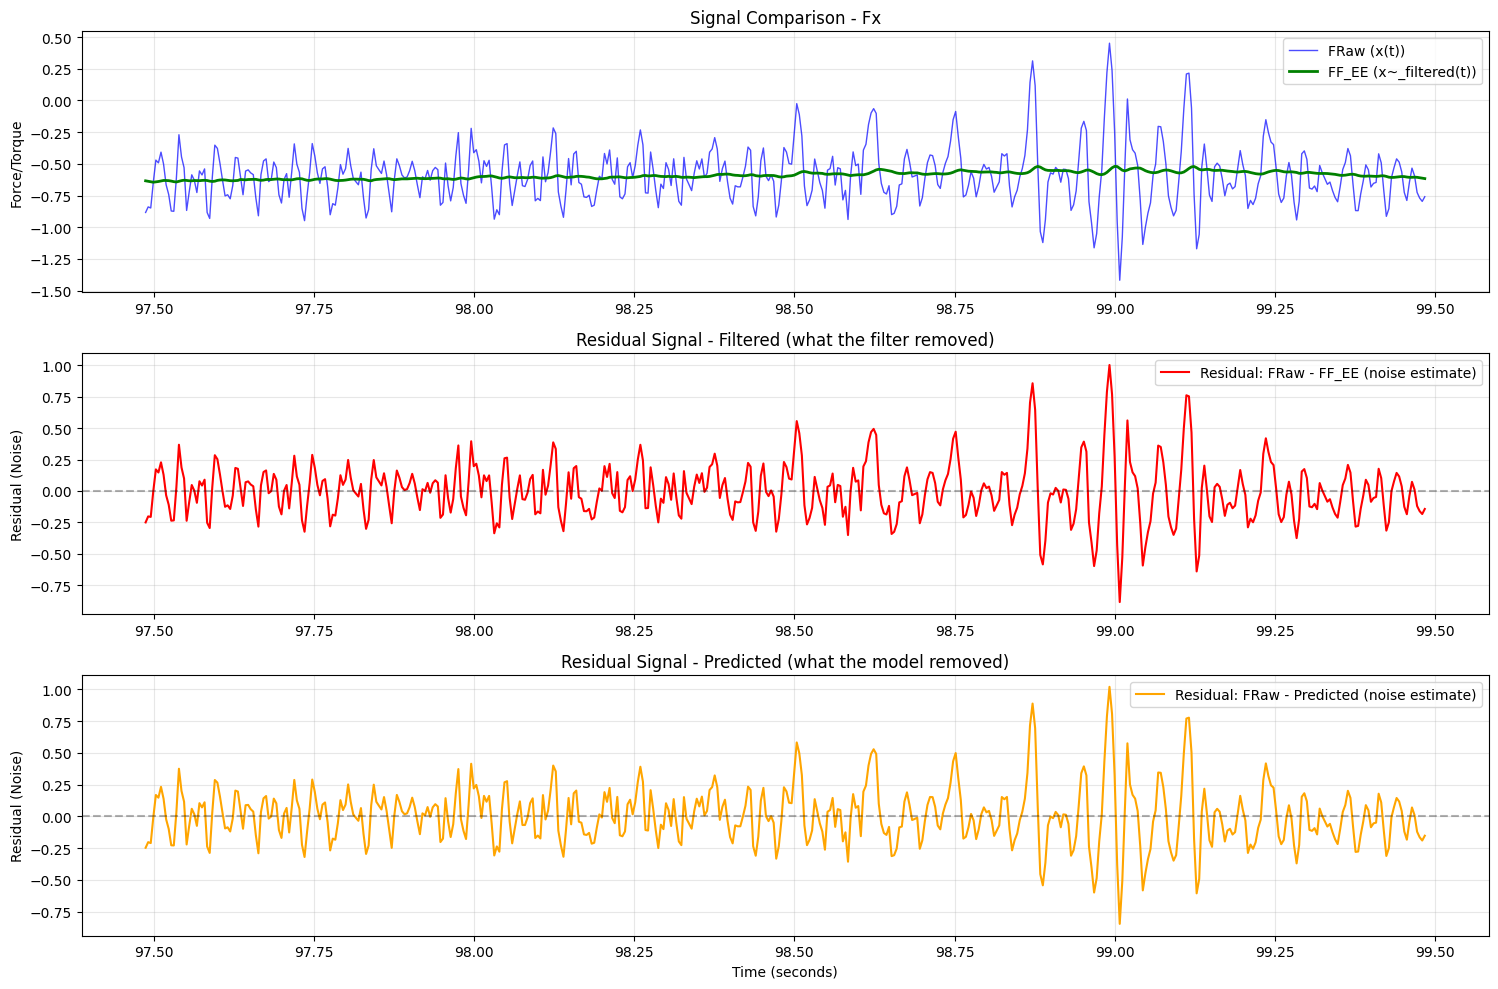


✓ Residual signals computed
  The residual represents the noise component removed by filtering/prediction


In [2]:
# Step 1: Compute Residual Signals (Noise Estimates)
# r(t) = x(t) - x~(t)

print("=" * 80)
print("STEP 1: COMPUTING RESIDUAL SIGNALS (NOISE ESTIMATES)")
print("=" * 80)

# Residual for FF_EE (filtered vs raw)
residual_ffee = FRaw - FF_EE  # r_filtered(t) = x(t) - x~_filtered(t)

# Residual for predicted (predicted vs raw)
residual_pred = FRaw - predicted_force  # r_predicted(t) = x(t) - x~_predicted(t)

print(f"Residual shapes:")
print(f"  residual_ffee: {residual_ffee.shape}")
print(f"  residual_pred: {residual_pred.shape}")

# Visualize residuals for one dimension (Fx) to understand what we're measuring
dim_to_plot = 0  # Fx
time_window_seconds = 2
time_window_samples = int(time_window_seconds * mean_freq)
start_idx = len(FRaw) // 2

fig, axes = plt.subplots(3, 1, figsize=(15, 10))

time_axis = np.arange(start_idx, start_idx + time_window_samples) / mean_freq

# Plot 1: Raw vs Filtered signals
ax1 = axes[0]
ax1.plot(time_axis, FRaw[start_idx:start_idx+time_window_samples, dim_to_plot], 
         'b-', linewidth=1, alpha=0.7, label='FRaw (x(t))')
ax1.plot(time_axis, FF_EE[start_idx:start_idx+time_window_samples, dim_to_plot], 
         'g-', linewidth=2, label='FF_EE (x~_filtered(t))')
ax1.set_ylabel('Force/Torque')
ax1.set_title(f'Signal Comparison - {["Fx", "Fy", "Fz", "Mx", "My", "Mz"][dim_to_plot]}')
ax1.legend()
ax1.grid(True, alpha=0.3)

# Plot 2: Residual for FF_EE
ax2 = axes[1]
ax2.plot(time_axis, residual_ffee[start_idx:start_idx+time_window_samples, dim_to_plot], 
         'r-', linewidth=1.5, label='Residual: FRaw - FF_EE (noise estimate)')
ax2.axhline(y=0, color='k', linestyle='--', alpha=0.3)
ax2.set_ylabel('Residual (Noise)')
ax2.set_title('Residual Signal - Filtered (what the filter removed)')
ax2.legend()
ax2.grid(True, alpha=0.3)

# Plot 3: Residual for predicted
ax3 = axes[2]
ax3.plot(time_axis, residual_pred[start_idx:start_idx+time_window_samples, dim_to_plot], 
         'orange', linewidth=1.5, label='Residual: FRaw - Predicted (noise estimate)')
ax3.axhline(y=0, color='k', linestyle='--', alpha=0.3)
ax3.set_xlabel('Time (seconds)')
ax3.set_ylabel('Residual (Noise)')
ax3.set_title('Residual Signal - Predicted (what the model removed)')
ax3.legend()
ax3.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print("\n✓ Residual signals computed")
print("  The residual represents the noise component removed by filtering/prediction")


In [3]:
# Step 2: Calculate RMS Noise and RMS Raw

print("\n" + "=" * 80)
print("STEP 2: CALCULATING RMS VALUES")
print("=" * 80)

dim_names = ['Fx', 'Fy', 'Fz', 'Mx', 'My', 'Mz']
results = []

for dim in range(6):
    # RMS of raw signal
    rms_raw = np.sqrt(np.mean(FRaw[:, dim]**2))
    
    # RMS of residual (noise estimate) for FF_EE
    rms_noise_ffee = np.sqrt(np.mean(residual_ffee[:, dim]**2))
    
    # RMS of residual (noise estimate) for predicted
    rms_noise_pred = np.sqrt(np.mean(residual_pred[:, dim]**2))
    
    # Store results
    results.append({
        'dimension': dim_names[dim],
        'rms_raw': rms_raw,
        'rms_noise_ffee': rms_noise_ffee,
        'rms_noise_pred': rms_noise_pred
    })
    
    print(f"\n{dim_names[dim]}:")
    print(f"  RMS Raw: {rms_raw:.6f}")
    print(f"  RMS Noise (FF_EE residual): {rms_noise_ffee:.6f}")
    print(f"  RMS Noise (Predicted residual): {rms_noise_pred:.6f}")

rms_df = pd.DataFrame(results)
print("\n✓ RMS values calculated")



STEP 2: CALCULATING RMS VALUES

Fx:
  RMS Raw: 1.200298
  RMS Noise (FF_EE residual): 0.254926
  RMS Noise (Predicted residual): 0.256874

Fy:
  RMS Raw: 3.829249
  RMS Noise (FF_EE residual): 0.307235
  RMS Noise (Predicted residual): 0.309208

Fz:
  RMS Raw: 12.007966
  RMS Noise (FF_EE residual): 0.253094
  RMS Noise (Predicted residual): 0.255852

Mx:
  RMS Raw: 0.354393
  RMS Noise (FF_EE residual): 0.025575
  RMS Noise (Predicted residual): 0.025683

My:
  RMS Raw: 0.129651
  RMS Noise (FF_EE residual): 0.021376
  RMS Noise (Predicted residual): 0.021472

Mz:
  RMS Raw: 0.052384
  RMS Noise (FF_EE residual): 0.011216
  RMS Noise (Predicted residual): 0.011256

✓ RMS values calculated


In [4]:
# Step 3: Calculate Noise Reduction Percentage and Decibels

print("\n" + "=" * 80)
print("STEP 3: CALCULATING NOISE REDUCTION")
print("=" * 80)

noise_reduction_results = []

for dim in range(6):
    rms_raw = rms_df.iloc[dim]['rms_raw']
    rms_noise_ffee = rms_df.iloc[dim]['rms_noise_ffee']
    rms_noise_pred = rms_df.iloc[dim]['rms_noise_pred']
    
    # Noise Reduction Percentage: 100 × (1 - RMS_noise / RMS_raw)
    reduction_pct_ffee = 100 * (1 - rms_noise_ffee / rms_raw) if rms_raw > 0 else 0
    reduction_pct_pred = 100 * (1 - rms_noise_pred / rms_raw) if rms_raw > 0 else 0
    
    # Noise Reduction in Decibels: 20 × log10(RMS_raw / RMS_noise)
    reduction_db_ffee = 20 * np.log10(rms_raw / rms_noise_ffee) if rms_noise_ffee > 0 else 0
    reduction_db_pred = 20 * np.log10(rms_raw / rms_noise_pred) if rms_noise_pred > 0 else 0
    
    noise_reduction_results.append({
        'dimension': dim_names[dim],
        'reduction_pct_ffee': reduction_pct_ffee,
        'reduction_pct_pred': reduction_pct_pred,
        'reduction_db_ffee': reduction_db_ffee,
        'reduction_db_pred': reduction_db_pred
    })
    
    print(f"\n{dim_names[dim]}:")
    print(f"  FF_EE vs Raw:")
    print(f"    Noise Reduction: {reduction_pct_ffee:.2f}%")
    print(f"    Noise Reduction: {reduction_db_ffee:.2f} dB")
    print(f"  Predicted vs Raw:")
    print(f"    Noise Reduction: {reduction_pct_pred:.2f}%")
    print(f"    Noise Reduction: {reduction_db_pred:.2f} dB")

noise_reduction_df = pd.DataFrame(noise_reduction_results)
print("\n✓ Noise reduction calculated")



STEP 3: CALCULATING NOISE REDUCTION

Fx:
  FF_EE vs Raw:
    Noise Reduction: 78.76%
    Noise Reduction: 13.46 dB
  Predicted vs Raw:
    Noise Reduction: 78.60%
    Noise Reduction: 13.39 dB

Fy:
  FF_EE vs Raw:
    Noise Reduction: 91.98%
    Noise Reduction: 21.91 dB
  Predicted vs Raw:
    Noise Reduction: 91.93%
    Noise Reduction: 21.86 dB

Fz:
  FF_EE vs Raw:
    Noise Reduction: 97.89%
    Noise Reduction: 33.52 dB
  Predicted vs Raw:
    Noise Reduction: 97.87%
    Noise Reduction: 33.43 dB

Mx:
  FF_EE vs Raw:
    Noise Reduction: 92.78%
    Noise Reduction: 22.83 dB
  Predicted vs Raw:
    Noise Reduction: 92.75%
    Noise Reduction: 22.80 dB

My:
  FF_EE vs Raw:
    Noise Reduction: 83.51%
    Noise Reduction: 15.66 dB
  Predicted vs Raw:
    Noise Reduction: 83.44%
    Noise Reduction: 15.62 dB

Mz:
  FF_EE vs Raw:
    Noise Reduction: 78.59%
    Noise Reduction: 13.39 dB
  Predicted vs Raw:
    Noise Reduction: 78.51%
    Noise Reduction: 13.36 dB

✓ Noise reduction ca

In [5]:
# Summary Table
print("\n" + "=" * 80)
print("SUMMARY: NOISE REDUCTION RESULTS")
print("=" * 80)

summary_data = []
for dim in range(6):
    summary_data.append({
        'Dimension': dim_names[dim],
        'RMS Raw': f"{rms_df.iloc[dim]['rms_raw']:.6f}",
        'RMS Noise (FF_EE)': f"{rms_df.iloc[dim]['rms_noise_ffee']:.6f}",
        'RMS Noise (Predicted)': f"{rms_df.iloc[dim]['rms_noise_pred']:.6f}",
        'Reduction % (FF_EE)': f"{noise_reduction_df.iloc[dim]['reduction_pct_ffee']:.2f}%",
        'Reduction % (Predicted)': f"{noise_reduction_df.iloc[dim]['reduction_pct_pred']:.2f}%",
        'Reduction dB (FF_EE)': f"{noise_reduction_df.iloc[dim]['reduction_db_ffee']:.2f} dB",
        'Reduction dB (Predicted)': f"{noise_reduction_df.iloc[dim]['reduction_db_pred']:.2f} dB"
    })

summary_df = pd.DataFrame(summary_data)
print(summary_df.to_string(index=False))

# Calculate averages
print("\n" + "-" * 80)
print("AVERAGE NOISE REDUCTION (across all 6 dimensions):")
print("-" * 80)
print(f"FF_EE vs Raw:")
print(f"  Average Reduction: {noise_reduction_df['reduction_pct_ffee'].mean():.2f}%")
print(f"  Average Reduction: {noise_reduction_df['reduction_db_ffee'].mean():.2f} dB")
print(f"\nPredicted vs Raw:")
print(f"  Average Reduction: {noise_reduction_df['reduction_pct_pred'].mean():.2f}%")
print(f"  Average Reduction: {noise_reduction_df['reduction_db_pred'].mean():.2f} dB")



SUMMARY: NOISE REDUCTION RESULTS
Dimension   RMS Raw RMS Noise (FF_EE) RMS Noise (Predicted) Reduction % (FF_EE) Reduction % (Predicted) Reduction dB (FF_EE) Reduction dB (Predicted)
       Fx  1.200298          0.254926              0.256874              78.76%                  78.60%             13.46 dB                 13.39 dB
       Fy  3.829249          0.307235              0.309208              91.98%                  91.93%             21.91 dB                 21.86 dB
       Fz 12.007966          0.253094              0.255852              97.89%                  97.87%             33.52 dB                 33.43 dB
       Mx  0.354393          0.025575              0.025683              92.78%                  92.75%             22.83 dB                 22.80 dB
       My  0.129651          0.021376              0.021472              83.51%                  83.44%             15.66 dB                 15.62 dB
       Mz  0.052384          0.011216              0.011256       

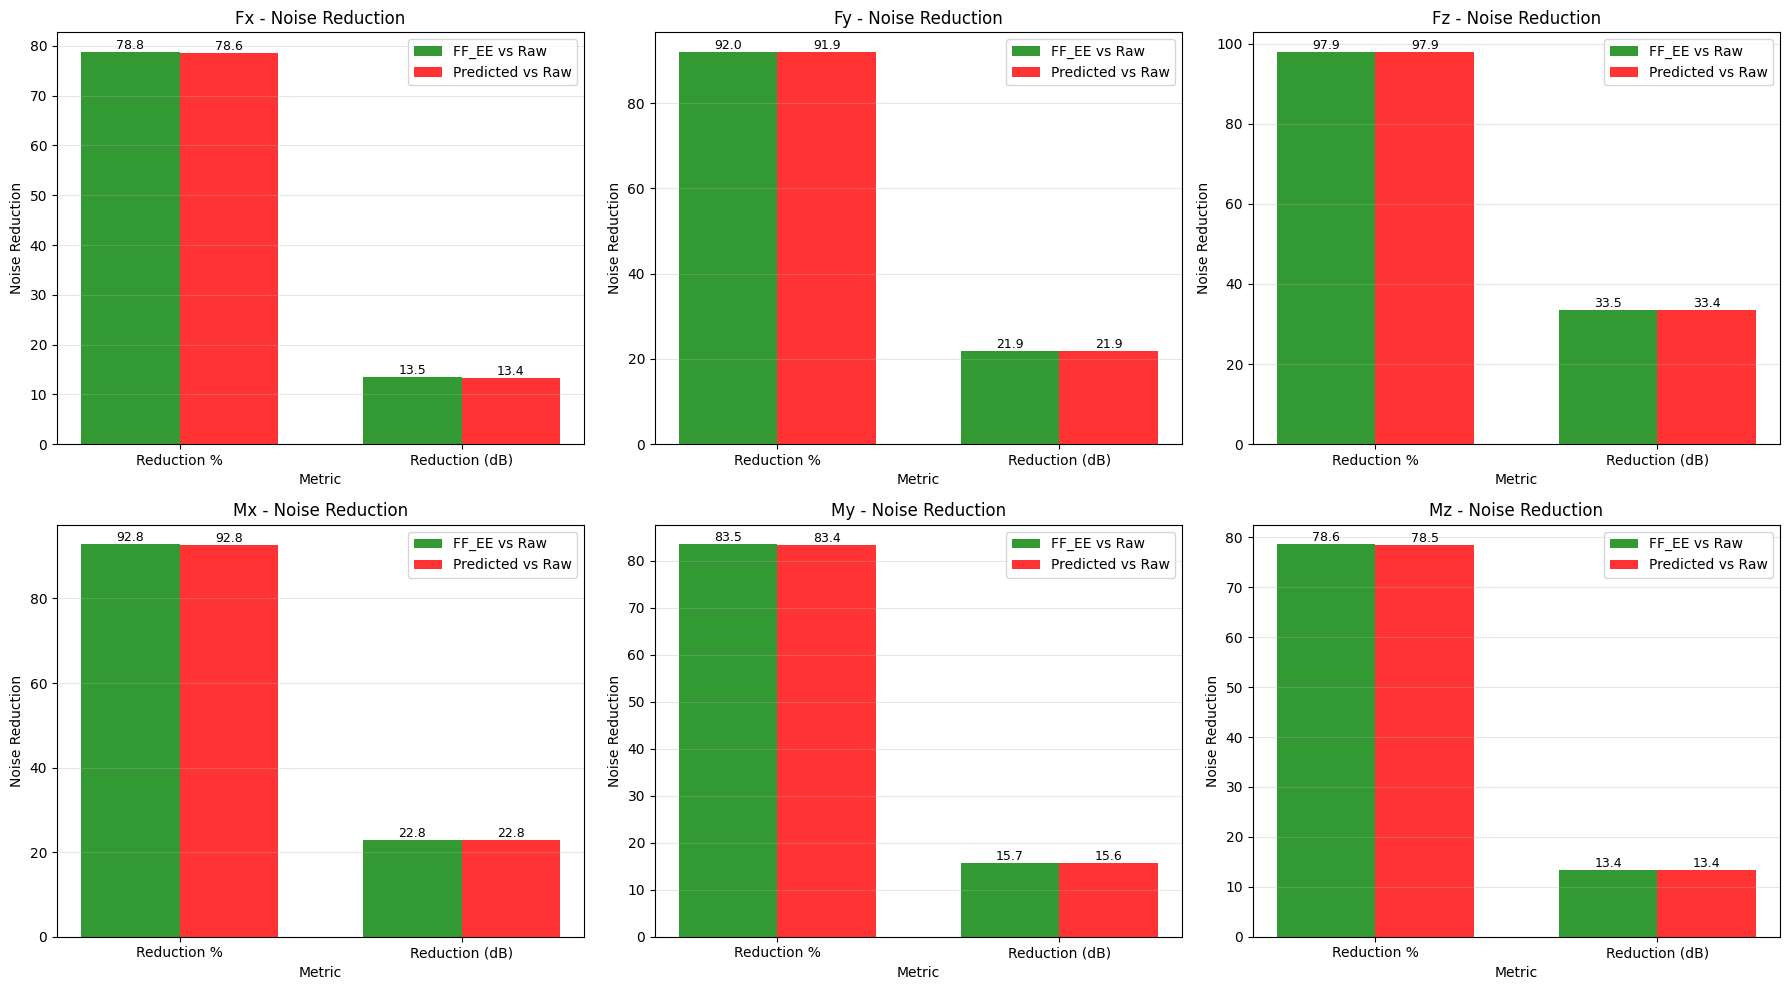

In [6]:
# Visualization: Noise Reduction Comparison (Bar Charts)
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for dim in range(6):
    ax = axes[dim]
    
    categories = ['Reduction %', 'Reduction (dB)']
    ffee_values = [
        noise_reduction_df.iloc[dim]['reduction_pct_ffee'],
        noise_reduction_df.iloc[dim]['reduction_db_ffee']
    ]
    pred_values = [
        noise_reduction_df.iloc[dim]['reduction_pct_pred'],
        noise_reduction_df.iloc[dim]['reduction_db_pred']
    ]
    
    x = np.arange(len(categories))
    width = 0.35
    
    bars1 = ax.bar(x - width/2, ffee_values, width, label='FF_EE vs Raw', alpha=0.8, color='green')
    bars2 = ax.bar(x + width/2, pred_values, width, label='Predicted vs Raw', alpha=0.8, color='red')
    
    ax.set_xlabel('Metric')
    ax.set_ylabel('Noise Reduction')
    ax.set_title(f'{dim_names[dim]} - Noise Reduction')
    ax.set_xticks(x)
    ax.set_xticklabels(categories)
    ax.legend()
    ax.grid(True, alpha=0.3, axis='y')
    ax.set_ylim(bottom=0)
    
    # Add value labels on bars
    for bars in [bars1, bars2]:
        for bar in bars:
            height = bar.get_height()
            ax.text(bar.get_x() + bar.get_width()/2., height,
                   f'{height:.1f}',
                   ha='center', va='bottom', fontsize=9)

plt.tight_layout()
plt.show()


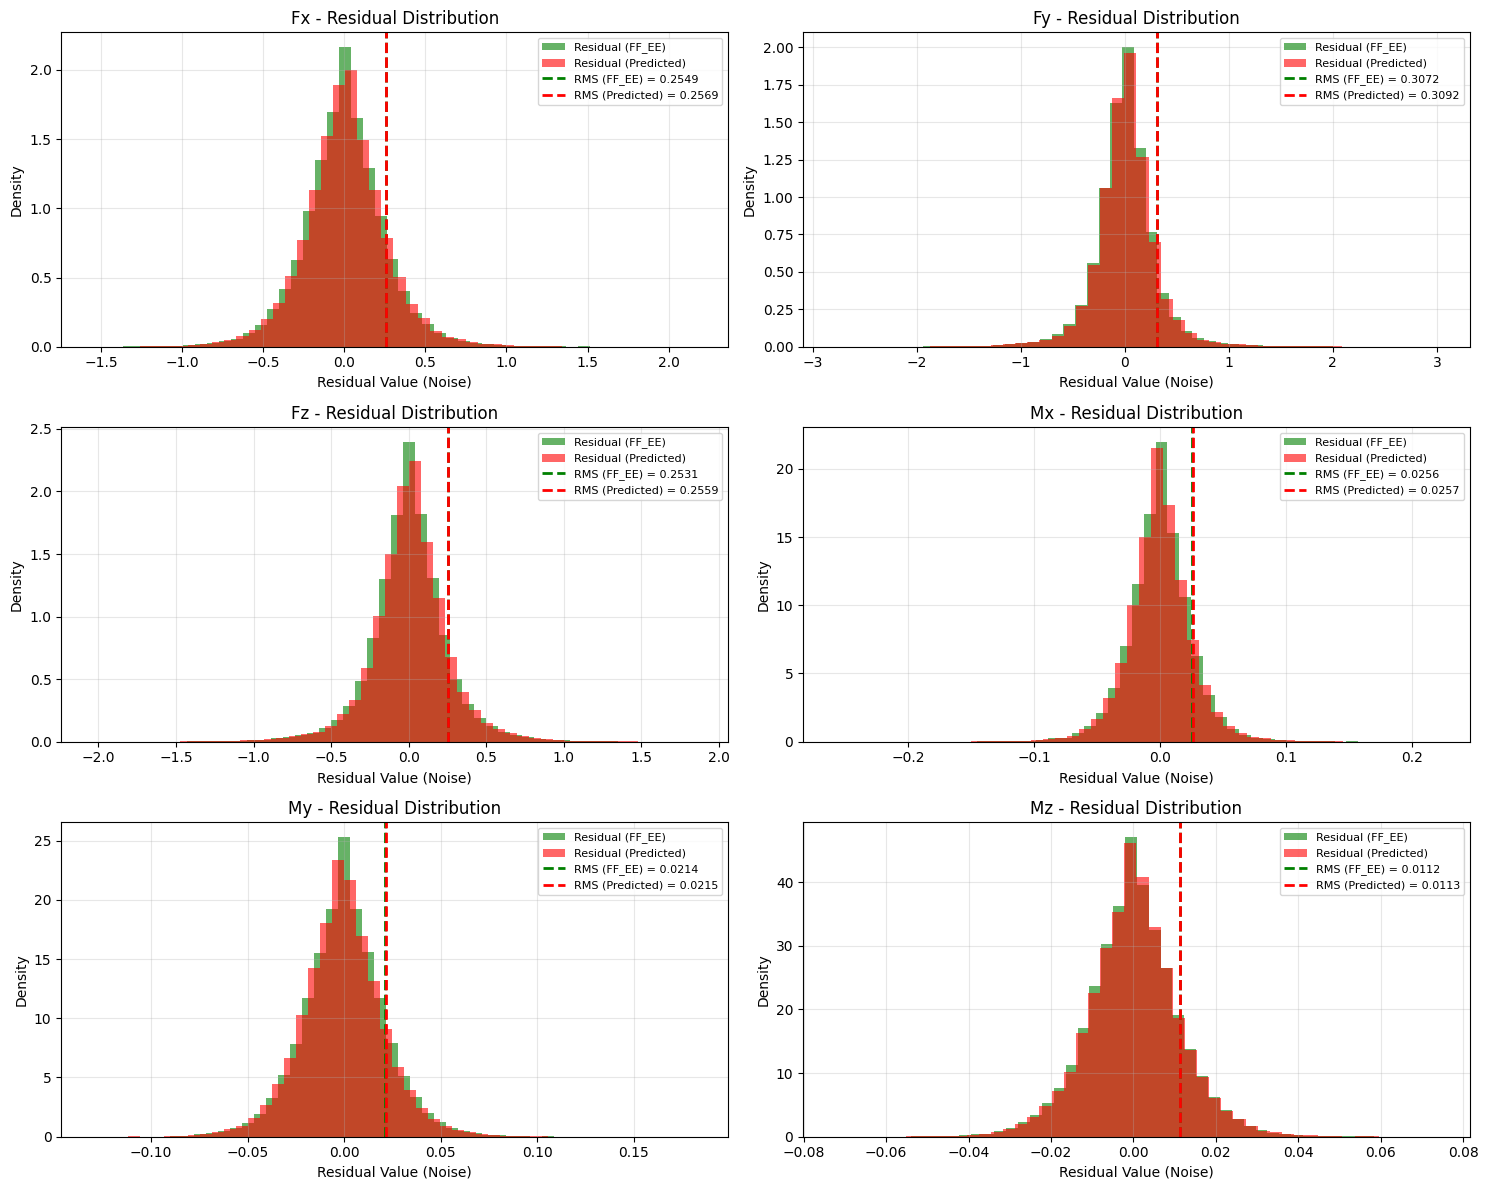

In [7]:
# Visualization: Residual Signal Statistics (Histograms)
fig, axes = plt.subplots(3, 2, figsize=(15, 12))
axes = axes.flatten()

for dim in range(6):
    ax = axes[dim]
    
    # Histogram of residuals
    ax.hist(residual_ffee[:, dim], bins=50, alpha=0.6, label='Residual (FF_EE)', color='green', density=True)
    ax.hist(residual_pred[:, dim], bins=50, alpha=0.6, label='Residual (Predicted)', color='red', density=True)
    
    # Add vertical lines for RMS values
    ax.axvline(x=rms_df.iloc[dim]['rms_noise_ffee'], color='green', linestyle='--', 
               linewidth=2, label=f'RMS (FF_EE) = {rms_df.iloc[dim]["rms_noise_ffee"]:.4f}')
    ax.axvline(x=rms_df.iloc[dim]['rms_noise_pred'], color='red', linestyle='--', 
               linewidth=2, label=f'RMS (Predicted) = {rms_df.iloc[dim]["rms_noise_pred"]:.4f}')
    
    ax.set_xlabel('Residual Value (Noise)')
    ax.set_ylabel('Density')
    ax.set_title(f'{dim_names[dim]} - Residual Distribution')
    ax.legend(fontsize=8)
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


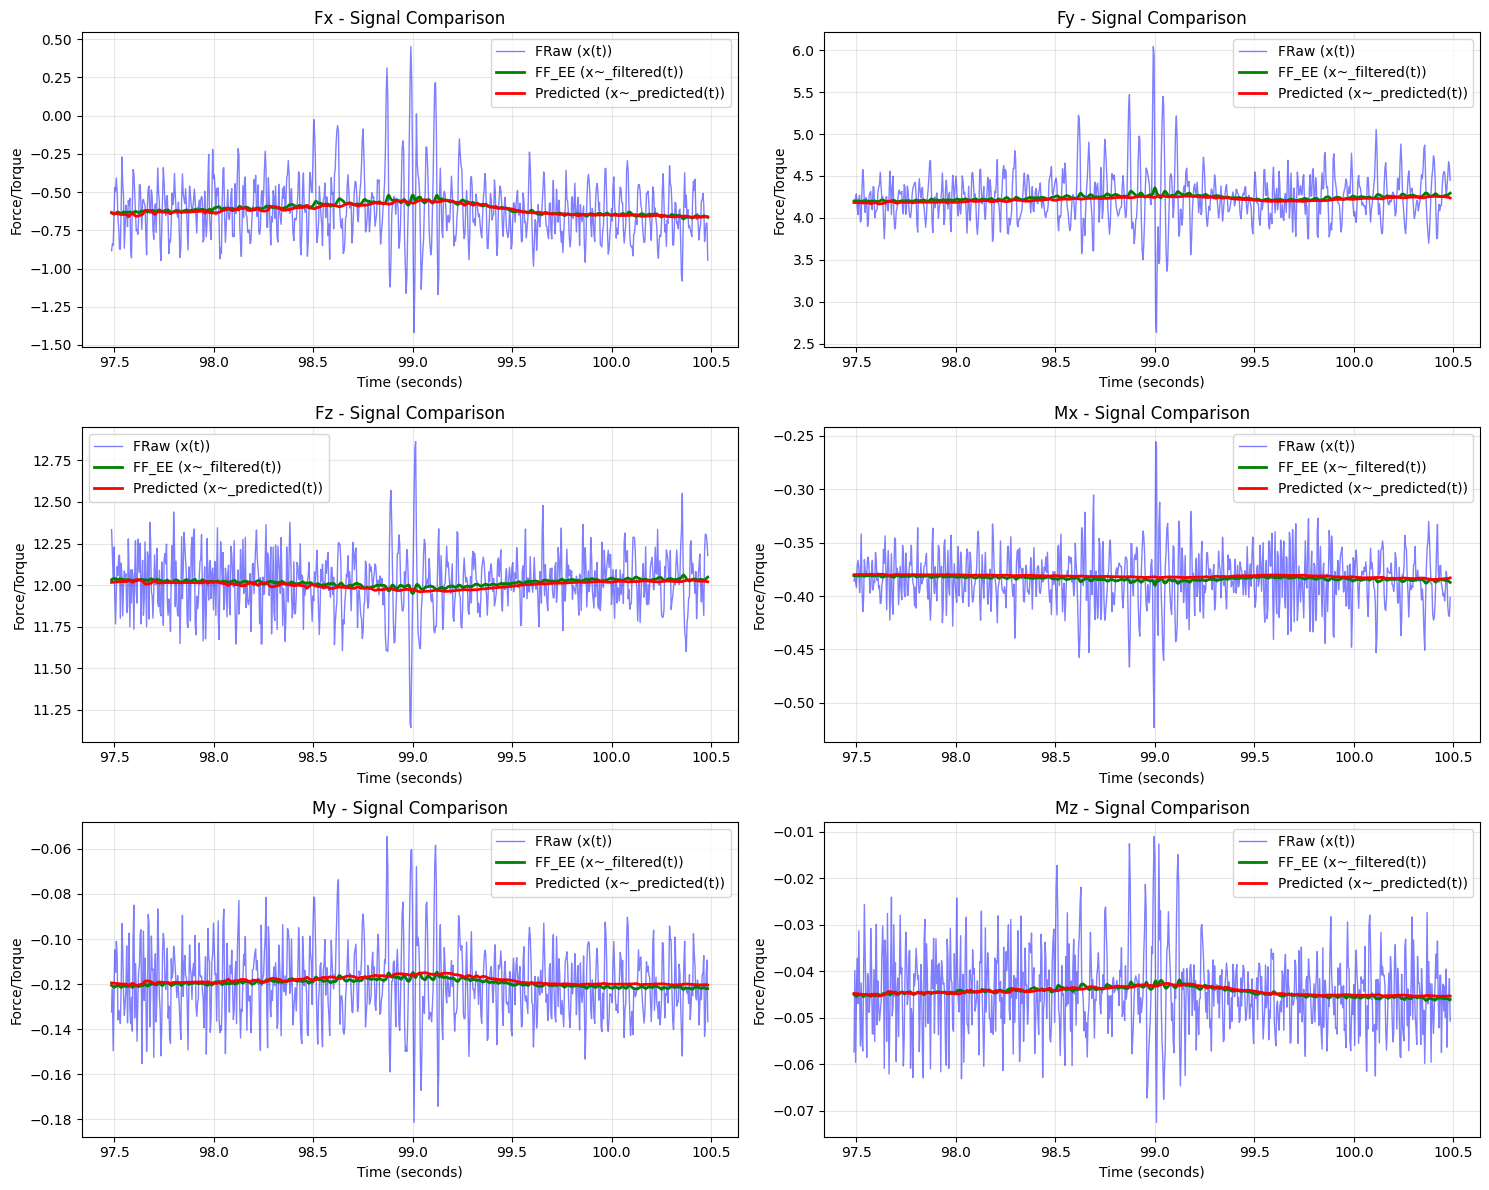

In [8]:
# Visualization: Signal Comparison Over Time
time_window_seconds = 3
time_window_samples = int(time_window_seconds * mean_freq)
start_idx = len(FRaw) // 2

fig, axes = plt.subplots(3, 2, figsize=(15, 12))
axes = axes.flatten()

time_axis = np.arange(start_idx, start_idx + time_window_samples) / mean_freq

for dim in range(6):
    ax = axes[dim]
    
    # Plot raw signal
    ax.plot(time_axis, FRaw[start_idx:start_idx+time_window_samples, dim], 
            'b-', linewidth=1, alpha=0.5, label='FRaw (x(t))')
    
    # Plot filtered signals
    ax.plot(time_axis, FF_EE[start_idx:start_idx+time_window_samples, dim], 
            'g-', linewidth=2, label='FF_EE (x~_filtered(t))')
    ax.plot(time_axis, predicted_force[start_idx:start_idx+time_window_samples, dim], 
            'r-', linewidth=2, label='Predicted (x~_predicted(t))')
    
    ax.set_xlabel('Time (seconds)')
    ax.set_ylabel('Force/Torque')
    ax.set_title(f'{dim_names[dim]} - Signal Comparison')
    ax.legend()
    ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()


In [9]:
# Export Results to JSON
print("\n" + "=" * 80)
print("EXPORTING RESULTS")
print("=" * 80)

# Create comprehensive summary report
summary_report = {
    'method': 'Residual Noise Method',
    'description': 'Noise reduction calculated using residual between raw and filtered/predicted signals',
    'formula_percentage': '100 × (1 - RMS_noise / RMS_raw)',
    'formula_decibels': '20 × log10(RMS_raw / RMS_noise)',
    'analysis_date': pd.Timestamp.now().strftime('%Y-%m-%d %H:%M:%S'),
    'total_samples': len(data_points),
    'sampling_frequency_hz': float(mean_freq),
    'per_dimension_results': []
}

for dim in range(6):
    summary_report['per_dimension_results'].append({
        'dimension': dim_names[dim],
        'rms_raw': float(rms_df.iloc[dim]['rms_raw']),
        'rms_noise_ffee': float(rms_df.iloc[dim]['rms_noise_ffee']),
        'rms_noise_predicted': float(rms_df.iloc[dim]['rms_noise_pred']),
        'noise_reduction_ffee': {
            'percentage': float(noise_reduction_df.iloc[dim]['reduction_pct_ffee']),
            'decibels': float(noise_reduction_df.iloc[dim]['reduction_db_ffee'])
        },
        'noise_reduction_predicted': {
            'percentage': float(noise_reduction_df.iloc[dim]['reduction_pct_pred']),
            'decibels': float(noise_reduction_df.iloc[dim]['reduction_db_pred'])
        }
    })

# Add averages
summary_report['averages'] = {
    'noise_reduction_ffee': {
        'percentage': float(noise_reduction_df['reduction_pct_ffee'].mean()),
        'decibels': float(noise_reduction_df['reduction_db_ffee'].mean())
    },
    'noise_reduction_predicted': {
        'percentage': float(noise_reduction_df['reduction_pct_pred'].mean()),
        'decibels': float(noise_reduction_df['reduction_db_pred'].mean())
    }
}

# Save to JSON
output_json = Path('residual_noise_reduction_summary.json')
with open(output_json, 'w') as f:
    json.dump(summary_report, f, indent=2)

print(f"✓ Results saved to {output_json}")
print(f"\nKey Findings:")
print(f"  Average noise reduction (FF_EE): {noise_reduction_df['reduction_pct_ffee'].mean():.2f}% ({noise_reduction_df['reduction_db_ffee'].mean():.2f} dB)")
print(f"  Average noise reduction (Predicted): {noise_reduction_df['reduction_pct_pred'].mean():.2f}% ({noise_reduction_df['reduction_db_pred'].mean():.2f} dB)")



EXPORTING RESULTS
✓ Results saved to residual_noise_reduction_summary.json

Key Findings:
  Average noise reduction (FF_EE): 87.25% (20.13 dB)
  Average noise reduction (Predicted): 87.18% (20.07 dB)


## Method Validation Notes

### Why This Method is Valid:

1. **No Ground Truth Required**: Works without knowing the true force
2. **Standard in Robotics**: Used in teleoperation, haptics, and force estimation papers
3. **Physically Meaningful**: The filtered signal represents smooth underlying force; the residual represents noise
4. **Works for Dynamic Motion**: No need for constant-force regions

### Interpretation:

- **High noise reduction %**: The filter/model successfully removed noise
- **Low noise reduction %**: The filter/model didn't remove much noise, or the "noise" contains actual signal components
- **Negative values**: Rare, but possible if the filtered signal has MORE variation than raw (unlikely for good filters)

### Comparison to Other Methods:

- **Variance reduction**: Similar but this method is more standard in robotics literature
- **Residual method**: Directly measures what was removed, which is the noise estimate
- **Decibel scale**: Better for comparing across different signal magnitudes
